# Time Series Practice 2

## Tổng quan 5W1H

| Thành phần | Nội dung |
|---|---|
| **What — Làm gì?** | Phân tích Monthly Retail Sales qua EDA, ADF, differencing, ACF/PACF, ARIMA và đánh giá forecast. |
| **Why — Vì sao?** | Xác định stationarity, chọn transformation và ARIMA candidate có evidence, sau đó kiểm tra chất lượng forecast ngoài mẫu. |
| **Who — Dành cho ai?** | Người học và người review Practice 2 cần theo dõi quy trình phân tích có thể tái tạo. |
| **When — Khi nào?** | Dữ liệu tháng từ 1991-07 đến 2008-06; train/test được chia theo đúng thứ tự thời gian. |
| **Where — Thực hiện ở đâu?** | Notebook chính E1–E5, dùng `datasets/raw/a10.csv`; artifact được lưu trong `outputs/`. |
| **How — Thực hiện thế nào?** | EDA → ADF chuỗi gốc → log + first difference → ACF/PACF → fit ARIMA → residual diagnostics → forecast và metrics. |

## Nguồn dữ liệu

- Dataset theo đề bài: [Monthly Retail Sales (`a10.csv`)](https://raw.githubusercontent.com/selva86/datasets/master/a10.csv).

> **Phạm vi:** E1–E5 là phạm vi chính thức của Practice 2.

In [1]:
import sys

EXPECTED_PYTHON_MINOR = (3, 12)
if sys.version_info[:2] != EXPECTED_PYTHON_MINOR:
    raise RuntimeError(
        f'Practice 2 requires Python 3.12; current version is {sys.version.split()[0]}.'
    )

print('Python executable:', sys.executable)
print('Python version:', sys.version.split()[0])


Python executable: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/.venv/bin/python
Python version: 3.12.15


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import HTML, Image, Markdown, display
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.analysis.correlation import compute_acf_pacf_tables, validate_arima_candidates
from practice_2.analysis.forecasting import build_forecast_table, calculate_forecast_metrics, compute_residual_diagnostics, fit_arima_candidates, forecast_arima_candidates, largest_forecast_errors, seasonal_naive_forecast
from practice_2.analysis.stationarity import log_first_difference
from practice_2.visualization.plots import save_acf_pacf_plot, save_forecast_comparison_plot, save_residual_diagnostics_plot, save_series_plot

SEARCH_ROOTS = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
PROJECT_ROOT = next(
    (root for root in SEARCH_ROOTS if (root / 'datasets' / 'raw' / 'a10.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Practice 2 root was not found from the working directory.')
RAW_PATH = PROJECT_ROOT / 'datasets' / 'raw' / 'a10.csv'
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
TABLE_THEME_PATH = PROJECT_ROOT / 'notebooks' / 'styles' / 'table_theme.css'
display(HTML(f'<style>{TABLE_THEME_PATH.read_text(encoding="utf-8")}</style>'))


# Exercise 1 — Khám phá dữ liệu (EDA)
<a id="exercise-1"></a>

### 1. Nạp dữ liệu

In [3]:
raw_frame = pd.read_csv(RAW_PATH)
raw_schema = pd.DataFrame({'column': raw_frame.columns, 'dtype': raw_frame.dtypes.astype(str).values})
print('shape:', raw_frame.shape)
raw_frame.info()
display(Markdown('**5 dòng đầu của dữ liệu thô**'))
display(raw_frame.head())
display(Markdown('**Schema của dữ liệu thô**'))
display(raw_schema)
series = load_monthly_retail_sales(RAW_PATH)
train_series, test_series = chronological_split(series, train_fraction=0.80)
display(Markdown('**5 quan sát đầu của chuỗi thời gian đã chuẩn hóa**'))
display(series.head().rename('value').to_frame())


shape: (204, 2)
<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    204 non-null    str    
 1   value   204 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.3 KB


**5 dòng đầu của dữ liệu thô**

,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


**Schema của dữ liệu thô**

,column,dtype
0,date,str
1,value,float64


**5 quan sát đầu của chuỗi thời gian đã chuẩn hóa**

,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


### 2. Kiểm tra data contract và time index

Kiểm tra schema, date range, monthly frequency, chronology, missing values, duplicate timestamps và missing intervals.

In [4]:
expected_index = pd.date_range(series.index.min(), series.index.max(), freq='MS')
validation = pd.DataFrame({'metric':['rows','start','end','index_type','frequency','missing_values','duplicate_timestamps','missing_intervals','chronological'],'value':[len(series),series.index.min(),series.index.max(),type(series.index).__name__,series.index.freqstr,int(series.isna().sum()),int(series.index.has_duplicates),len(expected_index.difference(series.index)),series.index.is_monotonic_increasing]})
boundary = pd.DataFrame({'split':['train','test'],'start':[train_series.index.min(),test_series.index.min()],'end':[train_series.index.max(),test_series.index.max()],'observations':[len(train_series),len(test_series)],'forecast_horizon':[None,len(test_series)]})
validation.to_csv(RESULTS_DIR / 'dataset_validation.csv', index=False); boundary.to_csv(RESULTS_DIR / 'train_test_boundary.csv', index=False)
display(Markdown('**Kết quả kiểm tra data contract**'))
display(validation)
display(Markdown('**Ranh giới chronological train/test split**'))
display(boundary)


**Kết quả kiểm tra data contract**

,metric,value
0,rows,204
1,start,1991-07-01 00:00:00
2,end,2008-06-01 00:00:00
3,index_type,DatetimeIndex
4,frequency,MS
5,missing_values,0
6,duplicate_timestamps,0
7,missing_intervals,0
8,chronological,True


**Ranh giới chronological train/test split**

,split,start,end,observations,forecast_horizon
0,train,1991-07-01,2005-01-01,163,NaN
1,test,2005-02-01,2008-06-01,41,41.0


### 3. Thống kê mô tả

In [5]:
descriptive = series.describe().to_frame('value').T
rolling_std_first = float(series.iloc[:24].std())
rolling_std_last = float(series.iloc[-24:].std())
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
potential_outliers = series[(series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)]
display(Markdown('**Thống kê mô tả toàn bộ chuỗi**'))
display(descriptive)
display(Markdown('**Độ biến động và kiểm tra outlier sơ bộ**'))
display(pd.DataFrame({'metric':['first_24_std','last_24_std','q1','q3','iqr','potential_outlier_count'],'value':[rolling_std_first,rolling_std_last,q1,q3,iqr,len(potential_outliers)]}))


**Thống kê mô tả toàn bộ chuỗi**

,count,mean,std,min,25%,50%,75%,max
value,204.0,10.69443,5.956998,2.81452,5.844095,9.319345,14.289964,29.665356


**Độ biến động và kiểm tra outlier sơ bộ**

,metric,value
0,first_24_std,0.829561
1,last_24_std,3.511456
2,q1,5.844095
3,q3,14.289964
4,iqr,8.445869
5,potential_outlier_count,2.000000


### 4. Biểu đồ chuỗi thời gian

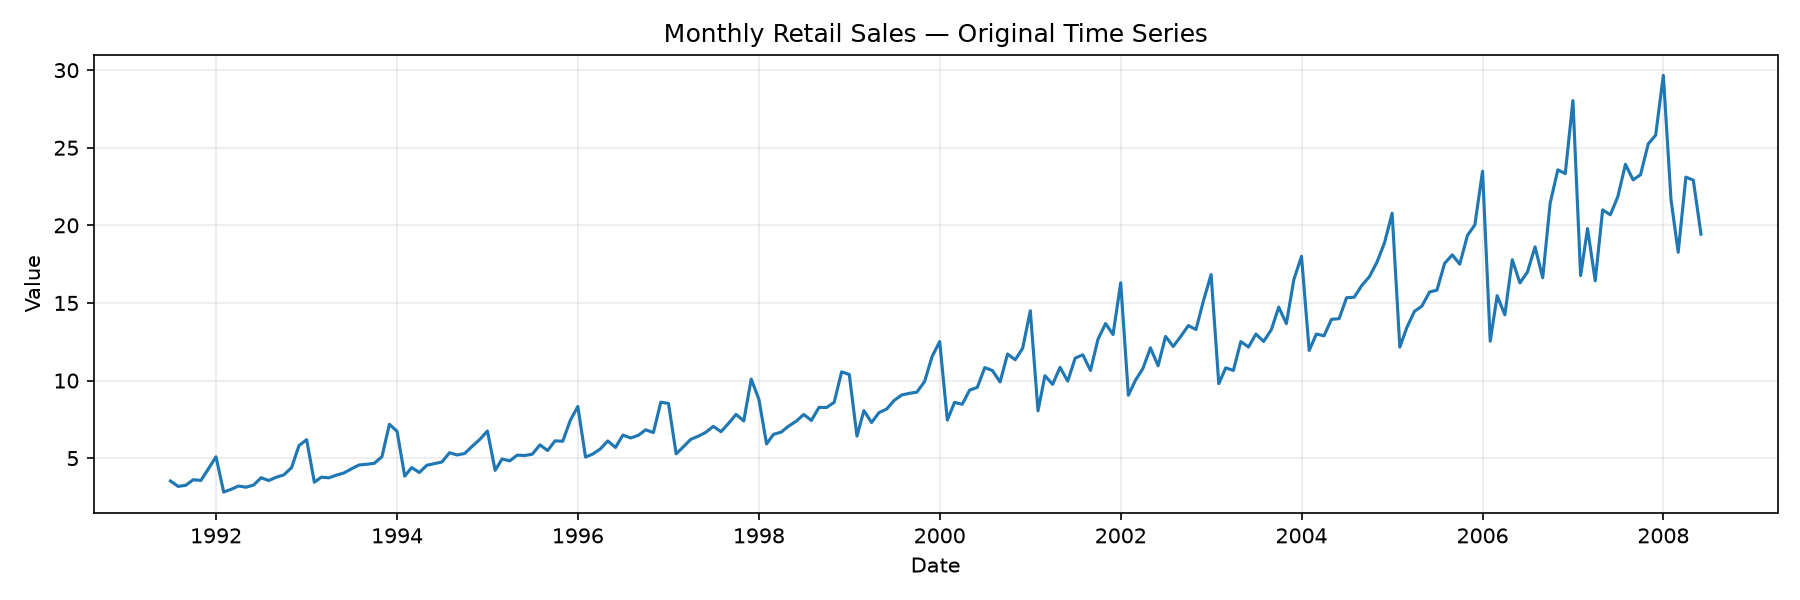

In [6]:
figure_path = FIGURES_DIR / '01_original_time_series.png'
save_series_plot(series, figure_path, 'Monthly Retail Sales — Original Time Series', 'Value')
display(Image(filename=str(figure_path)))


### 5. Kết luận E01

- **Xu hướng:** tăng rõ theo thời gian.
- **Mùa vụ:** có dấu hiệu lặp theo chu kỳ 12 tháng.
- **Tính dừng:** chuỗi có khả năng không dừng; kiểm định chính thức ở E02.

# Exercise 2 — Kiểm định ADF trên chuỗi gốc
<a id="exercise-2"></a>

### 1. Kiểm định ADF

**H₀:** chuỗi có unit root. Ngưỡng kiểm định: `α = 0.05`.

### 2. Kết quả trên chuỗi train gốc

Input: 163 quan sát train; 41 quan sát test không được sử dụng.

In [7]:
from practice_2.analysis.stationarity import run_adf

ADF_ALPHA = 0.05
adf_original, critical_original = run_adf(train_series, alpha=ADF_ALPHA)
adf_original.to_csv(RESULTS_DIR / 'adf_original_series.csv', index=False)
critical_original.to_csv(RESULTS_DIR / 'adf_original_critical_values.csv', index=False)
adf_statistic = float(adf_original.loc[adf_original['metric'].eq('adf_statistic'), 'value'].iloc[0])
p_value = float(adf_original.loc[adf_original['metric'].eq('p_value'), 'value'].iloc[0])
critical_comparison = critical_original.copy()
critical_comparison['statistic_below_critical'] = adf_statistic < critical_comparison['value']
display(Markdown('**Kết quả ADF của chuỗi huấn luyện gốc**'))
display(adf_original)
display(Markdown('**Critical values của kiểm định ADF**'))
display(critical_original)
display(Markdown('**So sánh ADF statistic với critical values**'))
display(critical_comparison)


/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


**Kết quả ADF của chuỗi huấn luyện gốc**

,metric,value
0,adf_statistic,2.230893
1,p_value,0.998907
2,used_lag,14
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0


**Critical values của kiểm định ADF**

,critical_value,value
0,1%,-3.475325
1,5%,-2.881275
2,10%,-2.577293


**So sánh ADF statistic với critical values**

,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết luận E02

ADF statistic = **2.230893**, p-value = **0.998907 > 0.05** → fail to reject H₀. Chuỗi train gốc **chưa dừng**.

# Exercise 3 — Sai phân và kiểm định lại
<a id="exercise-3"></a>

### 1. First difference trên chuỗi train

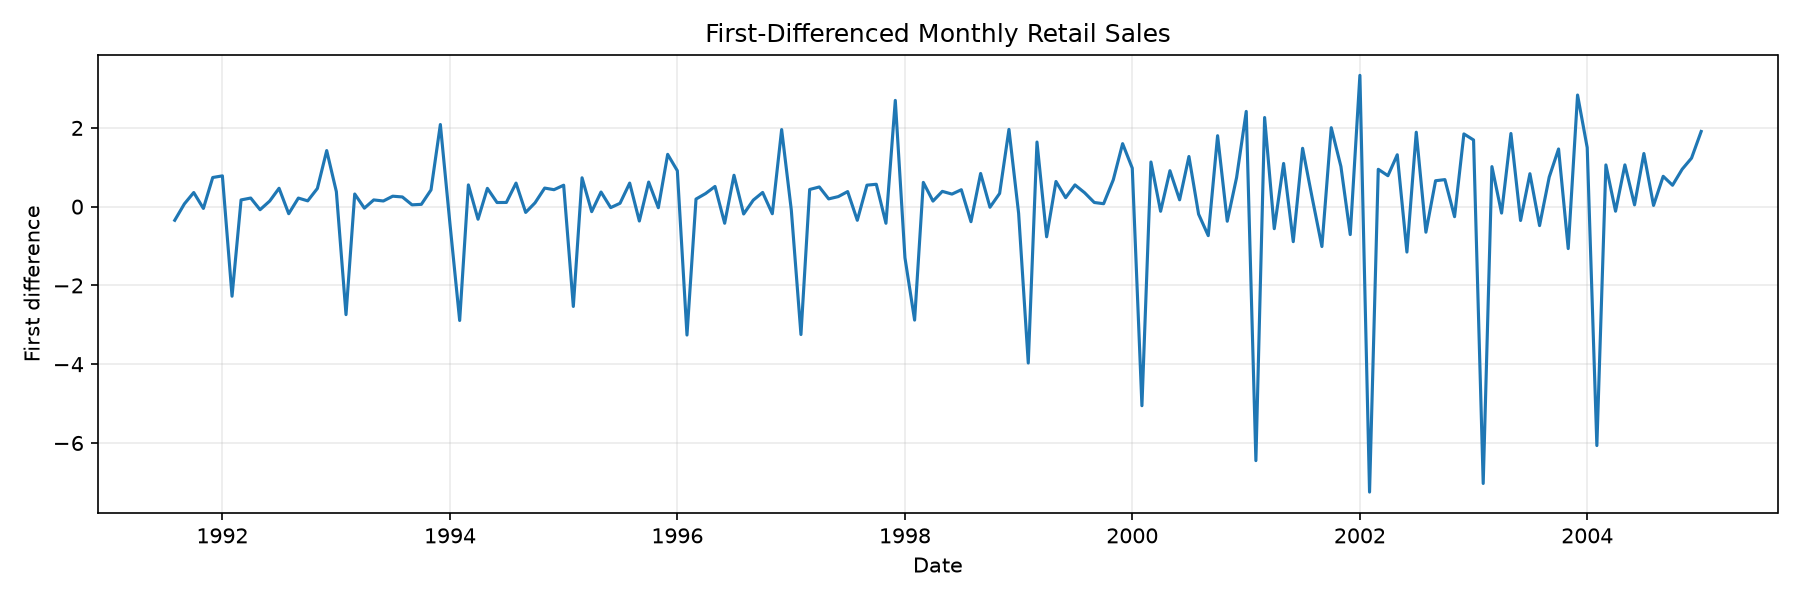

original training observations: 163
differenced observations: 162


In [8]:
from practice_2.analysis.stationarity import first_difference, log_first_difference

differenced = first_difference(train_series)
differenced_figure = FIGURES_DIR / '02_first_differenced_series.png'
save_series_plot(differenced, differenced_figure, 'First-Differenced Monthly Retail Sales', 'First difference')
display(Image(filename=str(differenced_figure)))
print('original training observations:', len(train_series))
print('differenced observations:', len(differenced))


### 2. ADF sau first difference

In [9]:
adf_diff, critical_diff = run_adf(differenced, alpha=ADF_ALPHA)
diff_statistic = float(adf_diff.loc[adf_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
diff_p_value = float(adf_diff.loc[adf_diff['metric'].eq('p_value'), 'value'].iloc[0])
raw_selected_d = 1 if diff_p_value <= ADF_ALPHA else 'REVIEW_REQUIRED'
diff_comparison = critical_diff.copy()
diff_comparison['statistic_below_critical'] = diff_statistic < diff_comparison['value']
raw_difference_decision = pd.concat([adf_diff, pd.DataFrame({'metric':['selected_d'], 'value':[raw_selected_d]})], ignore_index=True)
adf_diff.to_csv(RESULTS_DIR / 'adf_differenced_series.csv', index=False)
critical_diff.to_csv(RESULTS_DIR / 'adf_differenced_critical_values.csv', index=False)
display(Markdown('**Kết quả ADF sau first-order differencing trên thang gốc**'))
display(raw_difference_decision)
display(Markdown('**So sánh statistic và critical values sau differencing**'))
display(diff_comparison)


/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


**Kết quả ADF sau first-order differencing trên thang gốc**

,metric,value
0,adf_statistic,-1.706074
1,p_value,0.427986
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0
6,selected_d,REVIEW_REQUIRED


**So sánh statistic và critical values sau differencing**

,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết quả first difference

ADF statistic = **-1.706074**, p-value = **0.427986 > 0.05** → chuỗi vẫn chưa dừng.

### 4. Log transformation + first difference

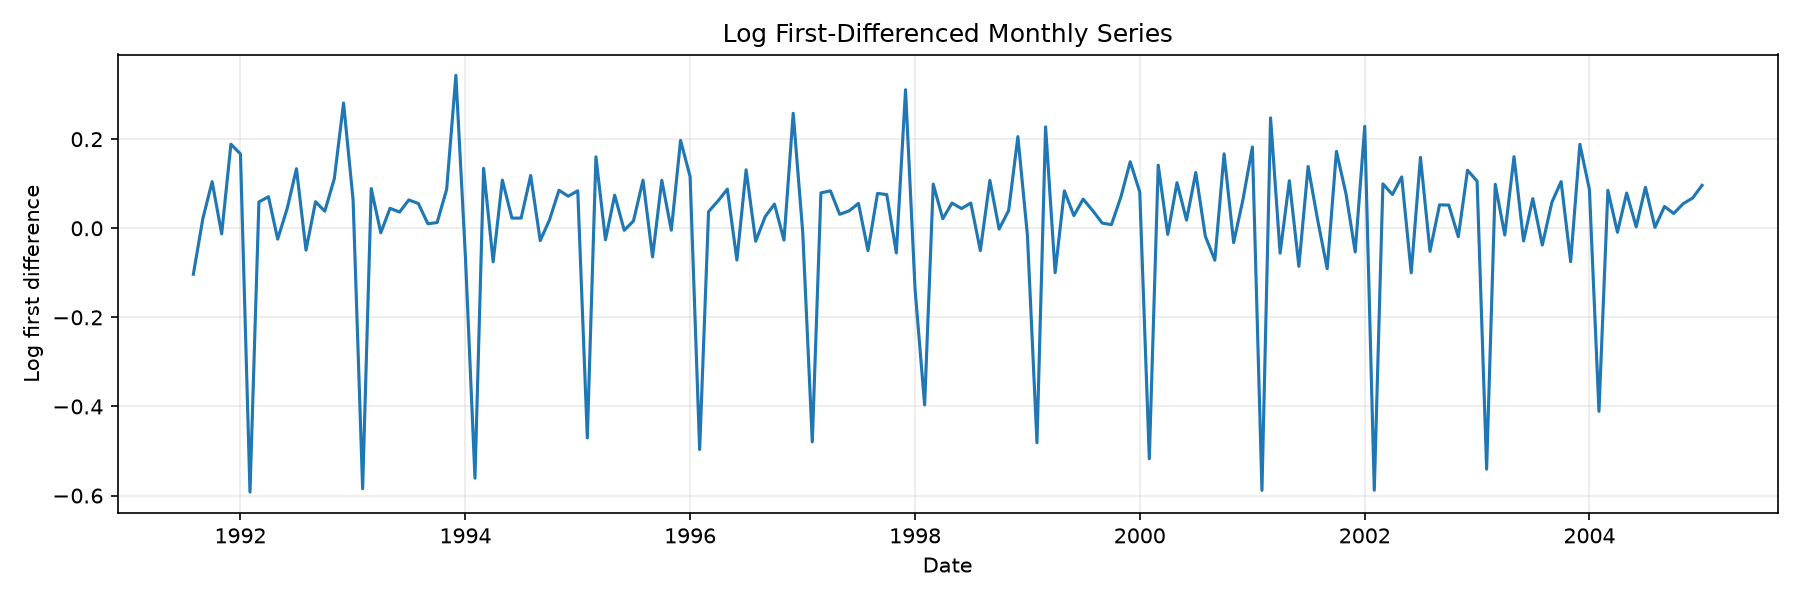

all training values positive: True
original training observations: 163
log first-differenced observations: 162
remaining missing values: 0


In [10]:
all_train_values_positive = bool((train_series > 0).all())
log_differenced = log_first_difference(train_series)
log_differenced_figure = FIGURES_DIR / '02_log_first_differenced_series.png'
save_series_plot(log_differenced, log_differenced_figure, 'Log First-Differenced Monthly Series', 'Log first difference')
display(Image(filename=str(log_differenced_figure)))
print('all training values positive:', all_train_values_positive)
print('original training observations:', len(train_series))
print('log first-differenced observations:', len(log_differenced))
print('remaining missing values:', int(log_differenced.isna().sum()))


In [11]:
adf_log_diff, critical_log_diff = run_adf(log_differenced, alpha=ADF_ALPHA)
log_diff_statistic = float(adf_log_diff.loc[adf_log_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
log_diff_p_value = float(adf_log_diff.loc[adf_log_diff['metric'].eq('p_value'), 'value'].iloc[0])
log_diff_decision = str(adf_log_diff.loc[adf_log_diff['metric'].eq('decision'), 'value'].iloc[0])
stationarity_supported = log_diff_p_value <= ADF_ALPHA
selected_d = 1 if stationarity_supported else 'REVIEW_REQUIRED'
selected_transformation = 'natural_log' if stationarity_supported else 'REVIEW_REQUIRED'
handoff_state = 'READY_FOR_E04_REVIEW' if stationarity_supported else 'CLOSED'
log_diff_comparison = critical_log_diff.copy()
log_diff_comparison['statistic_below_critical'] = log_diff_statistic < log_diff_comparison['value']
transformation_comparison = pd.DataFrame({'transformation':['raw_first_difference','log_first_difference'],'adf_statistic':[diff_statistic,log_diff_statistic],'p_value':[diff_p_value,log_diff_p_value],'decision':['fail to reject H0' if diff_p_value > ADF_ALPHA else 'reject H0',log_diff_decision]})
differencing_decision = pd.DataFrame({'metric':['analysis_series','transformation','regular_differencing_order','adf_statistic','p_value','alpha','decision','stationarity_supported','e04_handoff'],'value':['log_first_differenced_training',selected_transformation,selected_d,log_diff_statistic,log_diff_p_value,ADF_ALPHA,log_diff_decision,stationarity_supported,handoff_state]})
adf_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_series.csv', index=False)
critical_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_critical_values.csv', index=False)
transformation_comparison.to_csv(RESULTS_DIR / 'e03_transformation_comparison.csv', index=False)
differencing_decision.to_csv(RESULTS_DIR / 'differencing_decision.csv', index=False)
display(Markdown('**Kết quả ADF của log first-differenced training series**'))
display(adf_log_diff)
display(Markdown('**So sánh statistic và critical values trên chuỗi được chọn**'))
display(log_diff_comparison)
display(Markdown('**So sánh các phương án transformation**'))
display(transformation_comparison)
display(Markdown('**Quyết định differencing để bàn giao sang E4**'))
display(differencing_decision)

/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


**Kết quả ADF của log first-differenced training series**

,metric,value
0,adf_statistic,-3.659486
1,p_value,0.00472
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,reject H0


**So sánh statistic và critical values trên chuỗi được chọn**

,critical_value,value,statistic_below_critical
0,1%,-3.475325,True
1,5%,-2.881275,True
2,10%,-2.577293,True


**So sánh các phương án transformation**

,transformation,adf_statistic,p_value,decision
0,raw_first_difference,-1.706074,0.427986,fail to reject H0
1,log_first_difference,-3.659486,0.004720,reject H0


**Quyết định differencing để bàn giao sang E4**

,metric,value
0,analysis_series,log_first_differenced_training
1,transformation,natural_log
2,regular_differencing_order,1
3,adf_statistic,-3.659486
4,p_value,0.00472
5,alpha,0.05
6,decision,reject H0
7,stationarity_supported,True
8,e04_handoff,READY_FOR_E04_REVIEW


### 5. Kết luận E03

ADF statistic = **-3.659486**, p-value = **0.004720 < 0.05** → chuỗi `log + first difference` đã dừng. Chọn **`natural_log`** và **`d = 1`**.

# Exercise 4 — Phân tích ACF/PACF

### 1. Input từ E3

In [12]:
e04_series = log_differenced.copy()
assert len(e04_series) == 162
assert e04_series.notna().all()
assert e04_series.index[0] == train_series.index[1]
assert e04_series.index[-1] == train_series.index[-1]
assert e04_series.index.max() < test_series.index.min()

e04_input = pd.DataFrame({
    'series': ['log_first_differenced_training'],
    'observations': [len(e04_series)],
    'missing_values': [int(e04_series.isna().sum())],
    'start': [e04_series.index.min()],
    'end': [e04_series.index.max()],
    'test_start': [test_series.index.min()],
    'analysis_scale': ['natural_log'],
    'd': [1],
})
display(Markdown('**Dữ liệu đầu vào đã khóa cho E4**'))
display(e04_input)

**Dữ liệu đầu vào đã khóa cho E4**

,series,observations,missing_values,start,end,test_start,analysis_scale,d
0,log_first_differenced_training,162,0,1991-08-01,2005-01-01,2005-02-01,natural_log,1


In [13]:
acf_df, pacf_df = compute_acf_pacf_tables(
    e04_series, nlags=36, alpha=0.05, pacf_method='ywm'
)
acf_df.to_csv(RESULTS_DIR / 'acf_log_first_differenced.csv', index=False)
pacf_df.to_csv(RESULTS_DIR / 'pacf_log_first_differenced.csv', index=False)

### 2. Biểu đồ ACF/PACF

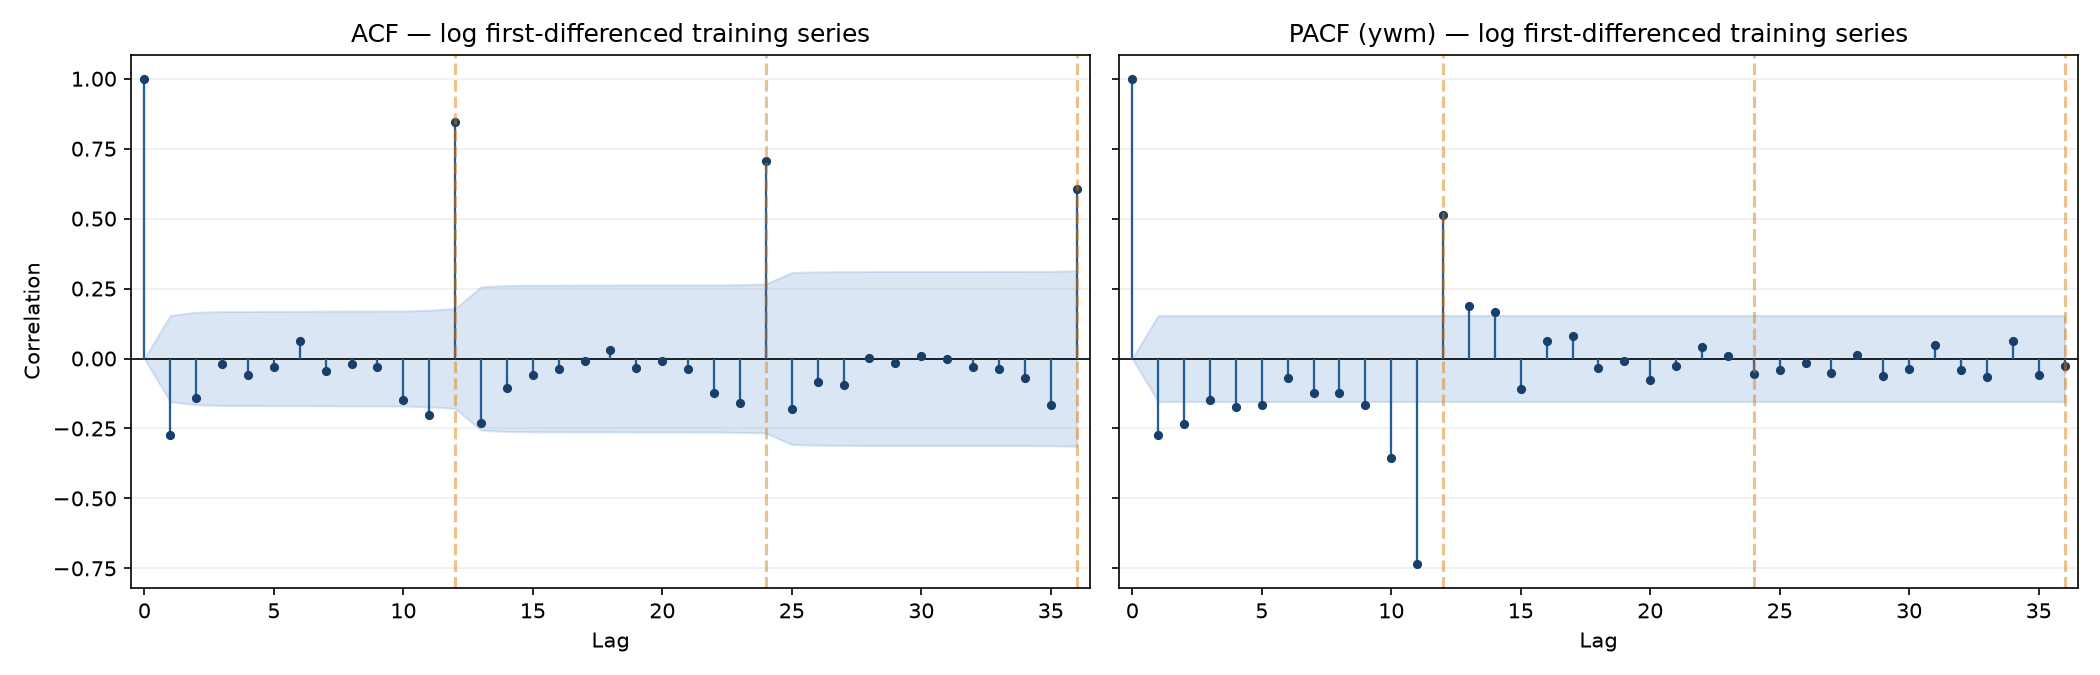

In [14]:
e04_figure = FIGURES_DIR / '03_acf_pacf_log_first_differenced.png'
save_acf_pacf_plot(acf_df, pacf_df, e04_figure)
display(Image(filename=str(e04_figure)))

### 3. Các lag nổi bật

In [15]:
significant_acf = acf_df.loc[(acf_df['lag'] > 0) & acf_df['significant']]
significant_pacf = pacf_df.loc[(pacf_df['lag'] > 0) & pacf_df['significant']]

In [16]:
display(Markdown('**Các ACF lags có ý nghĩa thống kê**'))
display(significant_acf[['lag', 'correlation', 'ci_lower', 'ci_upper']])

**Các ACF lags có ý nghĩa thống kê**

,lag,correlation,ci_lower,ci_upper
1,1,-0.273851,-0.427840,-0.119861
11,11,-0.200341,-0.373107,-0.027574
12,12,0.844390,0.666200,1.022580
24,24,0.704369,0.438051,0.970688
36,36,0.605161,0.291407,0.918915


In [17]:
display(Markdown('**Các PACF lags có ý nghĩa thống kê**'))
display(significant_pacf[['lag', 'correlation', 'ci_lower', 'ci_upper']])

**Các PACF lags có ý nghĩa thống kê**

,lag,correlation,ci_lower,ci_upper
1,1,-0.273851,-0.427840,-0.119861
2,2,-0.233715,-0.387705,-0.079726
4,4,-0.173273,-0.327262,-0.019284
5,5,-0.165465,-0.319454,-0.011476
9,9,-0.164863,-0.318853,-0.010874
10,10,-0.354953,-0.508943,-0.200964
11,11,-0.733289,-0.887278,-0.579300
12,12,0.512103,0.358114,0.666093
13,13,0.187122,0.033132,0.341111
14,14,0.164730,0.010741,0.318720


#### Lag mùa vụ 12, 24 và 36

In [18]:
seasonal_lags = [12, 24, 36]
seasonal_summary = acf_df.loc[acf_df['lag'].isin(seasonal_lags), ['lag', 'correlation', 'significant']].rename(
    columns={'correlation': 'acf', 'significant': 'acf_significant'}
).merge(
    pacf_df.loc[pacf_df['lag'].isin(seasonal_lags), ['lag', 'correlation', 'significant']].rename(
        columns={'correlation': 'pacf', 'significant': 'pacf_significant'}
    ),
    on='lag',
)
display(Markdown('**ACF/PACF tại các seasonal lags tham chiếu**'))
display(seasonal_summary)

**ACF/PACF tại các seasonal lags tham chiếu**

,lag,acf,acf_significant,pacf,pacf_significant
0,12,0.844390,True,0.512103,True
1,24,0.704369,True,-0.057087,False
2,36,0.605161,True,-0.027328,False


### 4. ARIMA candidates

In [19]:
candidate_table = validate_arima_candidates(pd.DataFrame({
    'candidate': ['ARIMA(1,1,1)', 'ARIMA(2,1,1)'],
    'p': pd.Series([1, 2], dtype=int),
    'd': pd.Series([1, 1], dtype=int),
    'q': pd.Series([1, 1], dtype=int),
    'analysis_scale': ['natural_log', 'natural_log'],
    'acf_evidence': [
        'ACF lag 1 significant; seasonal dependence remains at lags 12, 24, 36',
        'ACF lag 1 significant; seasonal dependence remains at lags 12, 24, 36',
    ],
    'pacf_evidence': [
        'PACF lag 1 significant; supports a parsimonious AR term',
        'PACF lags 1 and 2 significant; supports testing p=2',
    ],
    'status': ['provisional', 'provisional'],
}))
candidate_table.to_csv(RESULTS_DIR / 'arima_candidates.csv', index=False)
display(Markdown('**ARIMA candidates được đề xuất từ bằng chứng ACF/PACF**'))
display(candidate_table)

**ARIMA candidates được đề xuất từ bằng chứng ACF/PACF**

,candidate,p,d,q,analysis_scale,acf_evidence,pacf_evidence,status
0,"ARIMA(1,1,1)",1,1,1,natural_log,ACF lag 1 significant; seasonal dependence rem...,PACF lag 1 significant; supports a parsimoniou...,provisional
1,"ARIMA(2,1,1)",2,1,1,natural_log,ACF lag 1 significant; seasonal dependence rem...,PACF lags 1 and 2 significant; supports testin...,provisional


### 5. Kết luận E04

- ACF có tín hiệu ngắn hạn tại lag 1 và phụ thuộc mùa vụ mạnh tại lag 12, 24, 36; không thể kết luận ACF cắt hoàn toàn sau lag 1.
- PACF có tín hiệu tại lag 1–2 cùng nhiều lag quanh mùa vụ; lag 12 nổi bật, còn lag 24 và 36 không đáng kể theo PACF.
- Chuyển `ARIMA(1,1,1)` và `ARIMA(2,1,1)` sang E05 dưới dạng **provisional candidates** trên thang `natural_log`.
- Phụ thuộc mùa vụ còn mạnh là một giới hạn cần ghi nhận; E04 chưa fit model và chưa chọn mô hình cuối.

# Exercise 5 — ARIMA Forecasting and Evaluation

### 1. Setup và candidate handoff

In [20]:
e05_train = train_series.copy()
e05_test = test_series.copy()
assert len(e05_train) == 163 and len(e05_test) == 41
assert e05_train.index.max() < e05_test.index.min()

candidate_table = validate_arima_candidates(
    pd.read_csv(RESULTS_DIR / 'arima_candidates.csv')
)
e05_setup = pd.DataFrame({
    'train_observations': [len(e05_train)],
    'test_observations': [len(e05_test)],
    'train_end': [e05_train.index.max()],
    'test_start': [e05_test.index.min()],
    'shuffle': [False],
    'analysis_scale': ['natural_log'],
    'trend_policy': ["no drift (trend='n')"],
    'inverse_policy': ['exp(log forecast mean); no bias correction'],
})
display(Markdown('**Thiết lập train/test và modeling contract của E5**'))
display(e05_setup)

**Thiết lập train/test và modeling contract của E5**

,train_observations,test_observations,train_end,test_start,shuffle,analysis_scale,trend_policy,inverse_policy
0,163,41,2005-01-01,2005-02-01,False,natural_log,no drift (trend='n'),exp(log forecast mean); no bias correction


#### Candidate handoff từ E4

In [21]:
display(Markdown('**Các ARIMA candidates được đưa vào fitting**'))
display(candidate_table[['candidate', 'p', 'd', 'q', 'analysis_scale', 'status']])

**Các ARIMA candidates được đưa vào fitting**

,candidate,p,d,q,analysis_scale,status
0,"ARIMA(1,1,1)",1,1,1,natural_log,provisional
1,"ARIMA(2,1,1)",2,1,1,natural_log,provisional


### 2. Model fitting

In [22]:
fitted_models, fit_summary = fit_arima_candidates(e05_train, candidate_table)
if not fit_summary['converged'].all() or (fit_summary['warnings'] != 'none').any():
    raise RuntimeError('STOP: model failed convergence or emitted a fitting warning')
fit_summary.to_csv(RESULTS_DIR / '05_arima_fit_summary.csv', index=False)
display(Markdown('**Kết quả fitting và information criteria**'))
display(fit_summary)

**Kết quả fitting và information criteria**

,model,p,d,q,trend,drift_included,analysis_scale,n_train,converged,aic,bic,warnings
0,"ARIMA(1,1,1)",1,1,1,n,False,natural_log,163,True,-131.048881,-121.786092,none
1,"ARIMA(2,1,1)",2,1,1,n,False,natural_log,163,True,-129.532608,-117.182223,none


### 3. Residual diagnostics

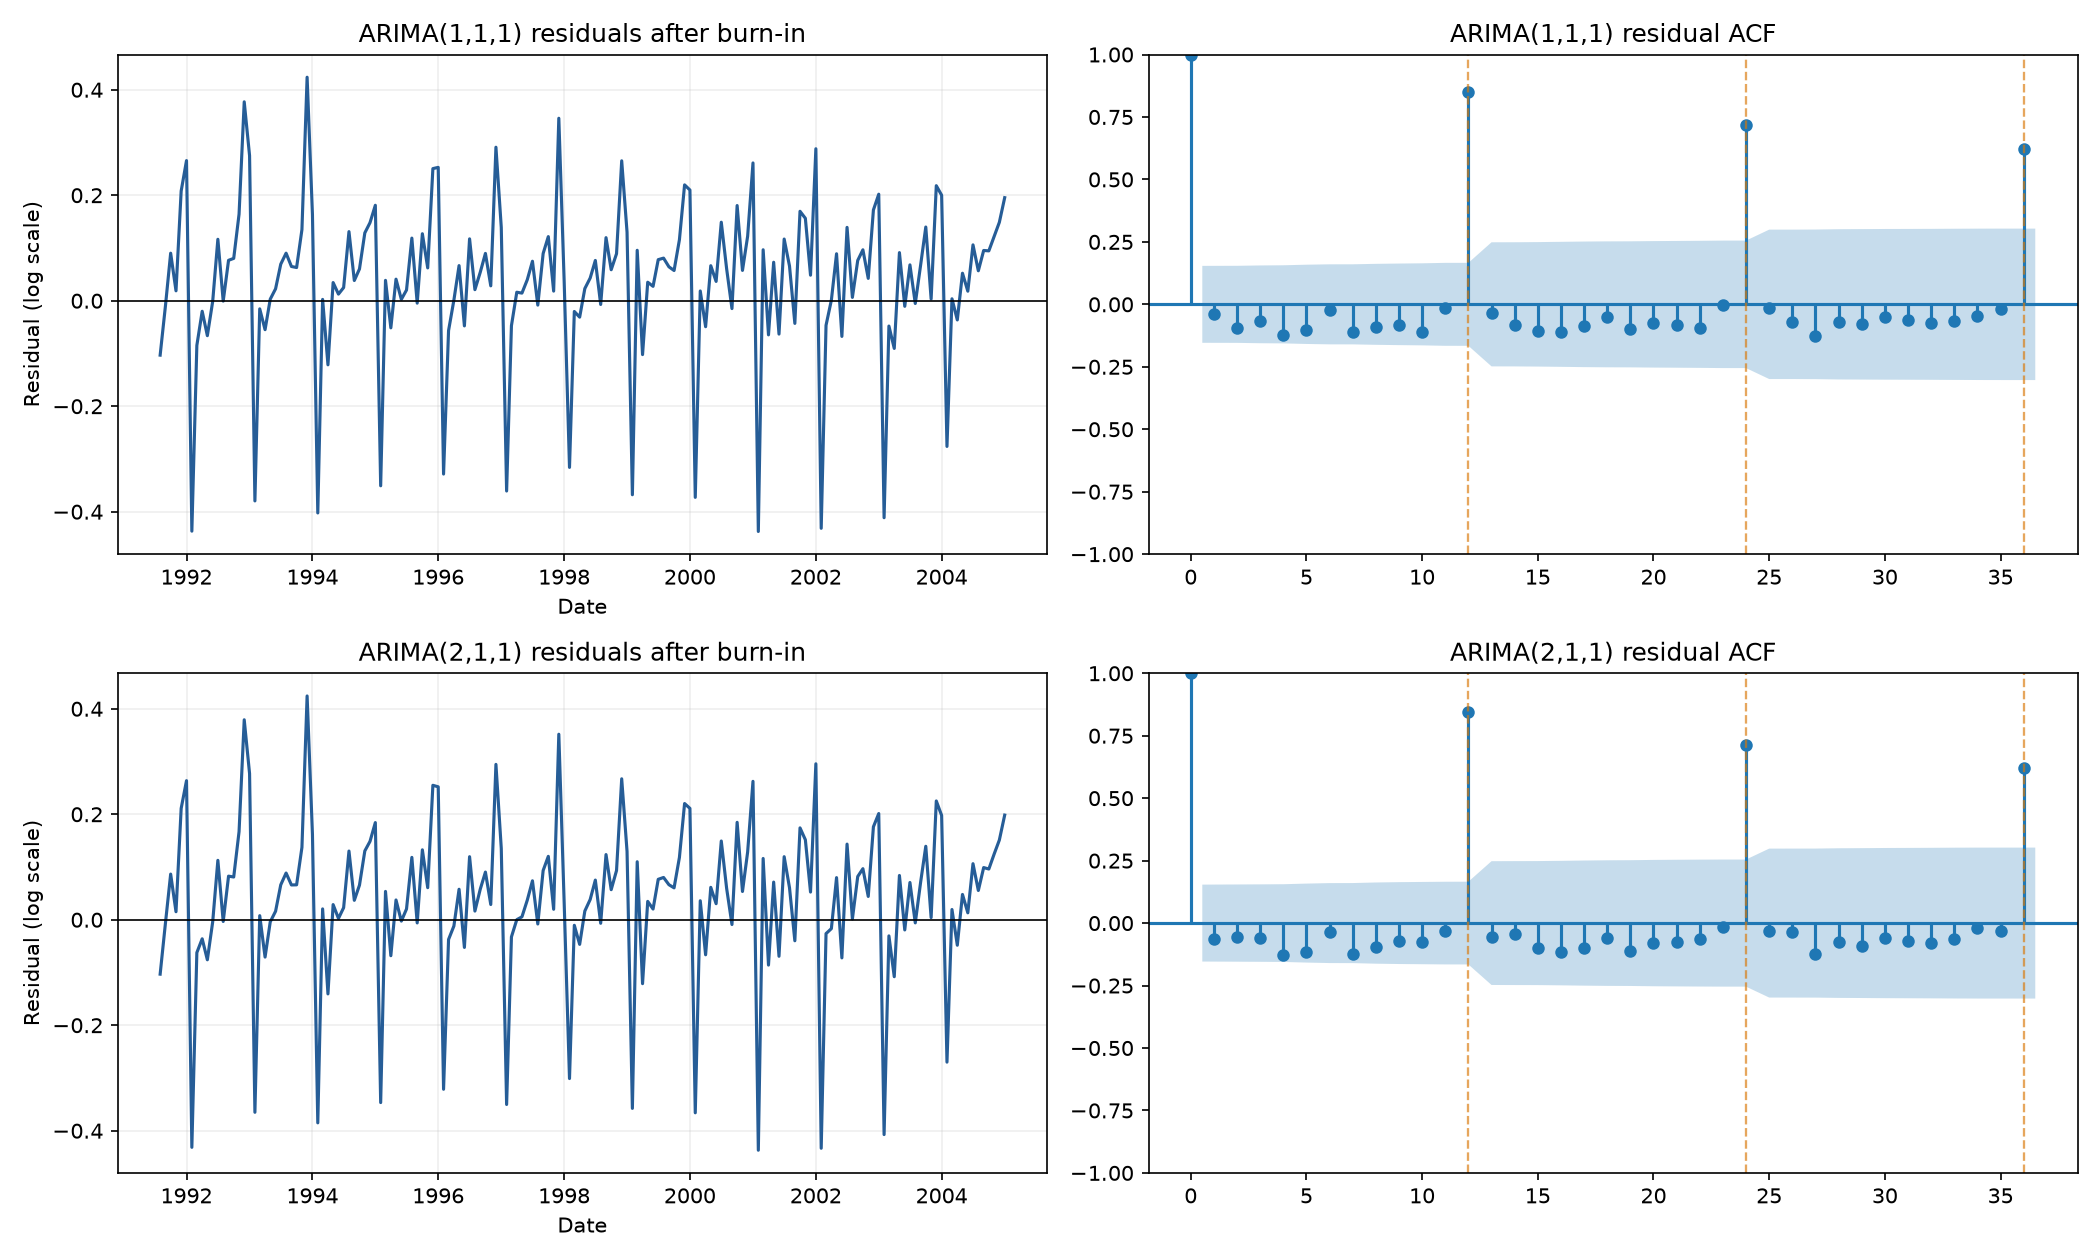

**Residual diagnostics của các ARIMA candidates**

,model,residual_mean,residual_observations,burn_in,lag,model_df,alpha,lb_stat,lb_pvalue,reject_no_autocorrelation,white_noise_supported
0,"ARIMA(1,1,1)",0.036686,162,1,12,2,0.05,141.289874,2.292669e-25,True,False
1,"ARIMA(1,1,1)",0.036686,162,1,24,2,0.05,253.225577,3.259832e-41,True,False
2,"ARIMA(2,1,1)",0.037050,162,1,12,3,0.05,140.169457,9.517944e-26,True,False
3,"ARIMA(2,1,1)",0.037050,162,1,24,3,0.05,251.126441,2.439552e-41,True,False


In [23]:
residuals_by_model, residual_summary = compute_residual_diagnostics(
    fitted_models, lags=(12, 24), alpha=0.05
)
residual_summary.to_csv(RESULTS_DIR / '05_arima_residual_diagnostics.csv', index=False)
residual_figure = FIGURES_DIR / '05_arima_residual_diagnostics.png'
save_residual_diagnostics_plot(residuals_by_model, residual_figure)
display(Image(filename=str(residual_figure)))
display(Markdown('**Residual diagnostics của các ARIMA candidates**'))
display(residual_summary)

### 4. Forecast và evaluation

In [24]:
e05_forecasts = forecast_arima_candidates(fitted_models, e05_test.index)
e05_forecasts['Seasonal naive (12)'] = seasonal_naive_forecast(
    e05_train, e05_test.index, seasonal_period=12
)
forecast_table = build_forecast_table(e05_test, e05_forecasts)
forecast_table.to_csv(RESULTS_DIR / '05_arima_forecasts.csv', index=False)

#### MAE, RMSE và MAPE

In [25]:
metrics_table = calculate_forecast_metrics(forecast_table)
largest_errors = largest_forecast_errors(forecast_table)
metrics_table.to_csv(RESULTS_DIR / '05_arima_metrics.csv', index=False)
metric_classes = pd.DataFrame('', index=metrics_table.index, columns=metrics_table.columns)
for metric_name in ['mae', 'rmse', 'mape_percent']:
    metric_classes.loc[metrics_table[metric_name].idxmin(), metric_name] = 'metric-best'
metrics_view = (
    metrics_table.style
    .format({'mae': '{:.3f}', 'rmse': '{:.3f}', 'mape_percent': '{:.3f}'})
    .set_td_classes(metric_classes)
    .set_table_attributes('class="dataframe practice2-table"')
)
display(Markdown('**So sánh forecast metrics — ô xanh là giá trị tốt nhất**'))
display(metrics_view)

test_mean = float(e05_test.mean())
best_arima = metrics_table[metrics_table['model'].str.startswith('ARIMA')].nsmallest(1, 'rmse')
rmse_context = pd.DataFrame({
    'best_arima': [best_arima.iloc[0]['model']],
    'rmse': [best_arima.iloc[0]['rmse']],
    'test_mean': [test_mean],
    'rmse_as_percent_of_test_mean': [best_arima.iloc[0]['rmse'] / test_mean * 100],
})
display(Markdown('**RMSE của ARIMA tốt nhất trong bối cảnh mức trung bình tập test**'))
display(rmse_context)

**So sánh forecast metrics — ô xanh là giá trị tốt nhất**

,model,mae,rmse,mape_percent
0,"ARIMA(1,1,1)",3.833,4.866,18.494
1,"ARIMA(2,1,1)",3.806,4.835,18.358
2,Seasonal naive (12),4.256,5.186,20.097


**RMSE của ARIMA tốt nhất trong bối cảnh mức trung bình tập test**

,best_arima,rmse,test_mean,rmse_as_percent_of_test_mean
0,"ARIMA(2,1,1)",4.834521,19.511879,24.77732


#### Forecast comparison

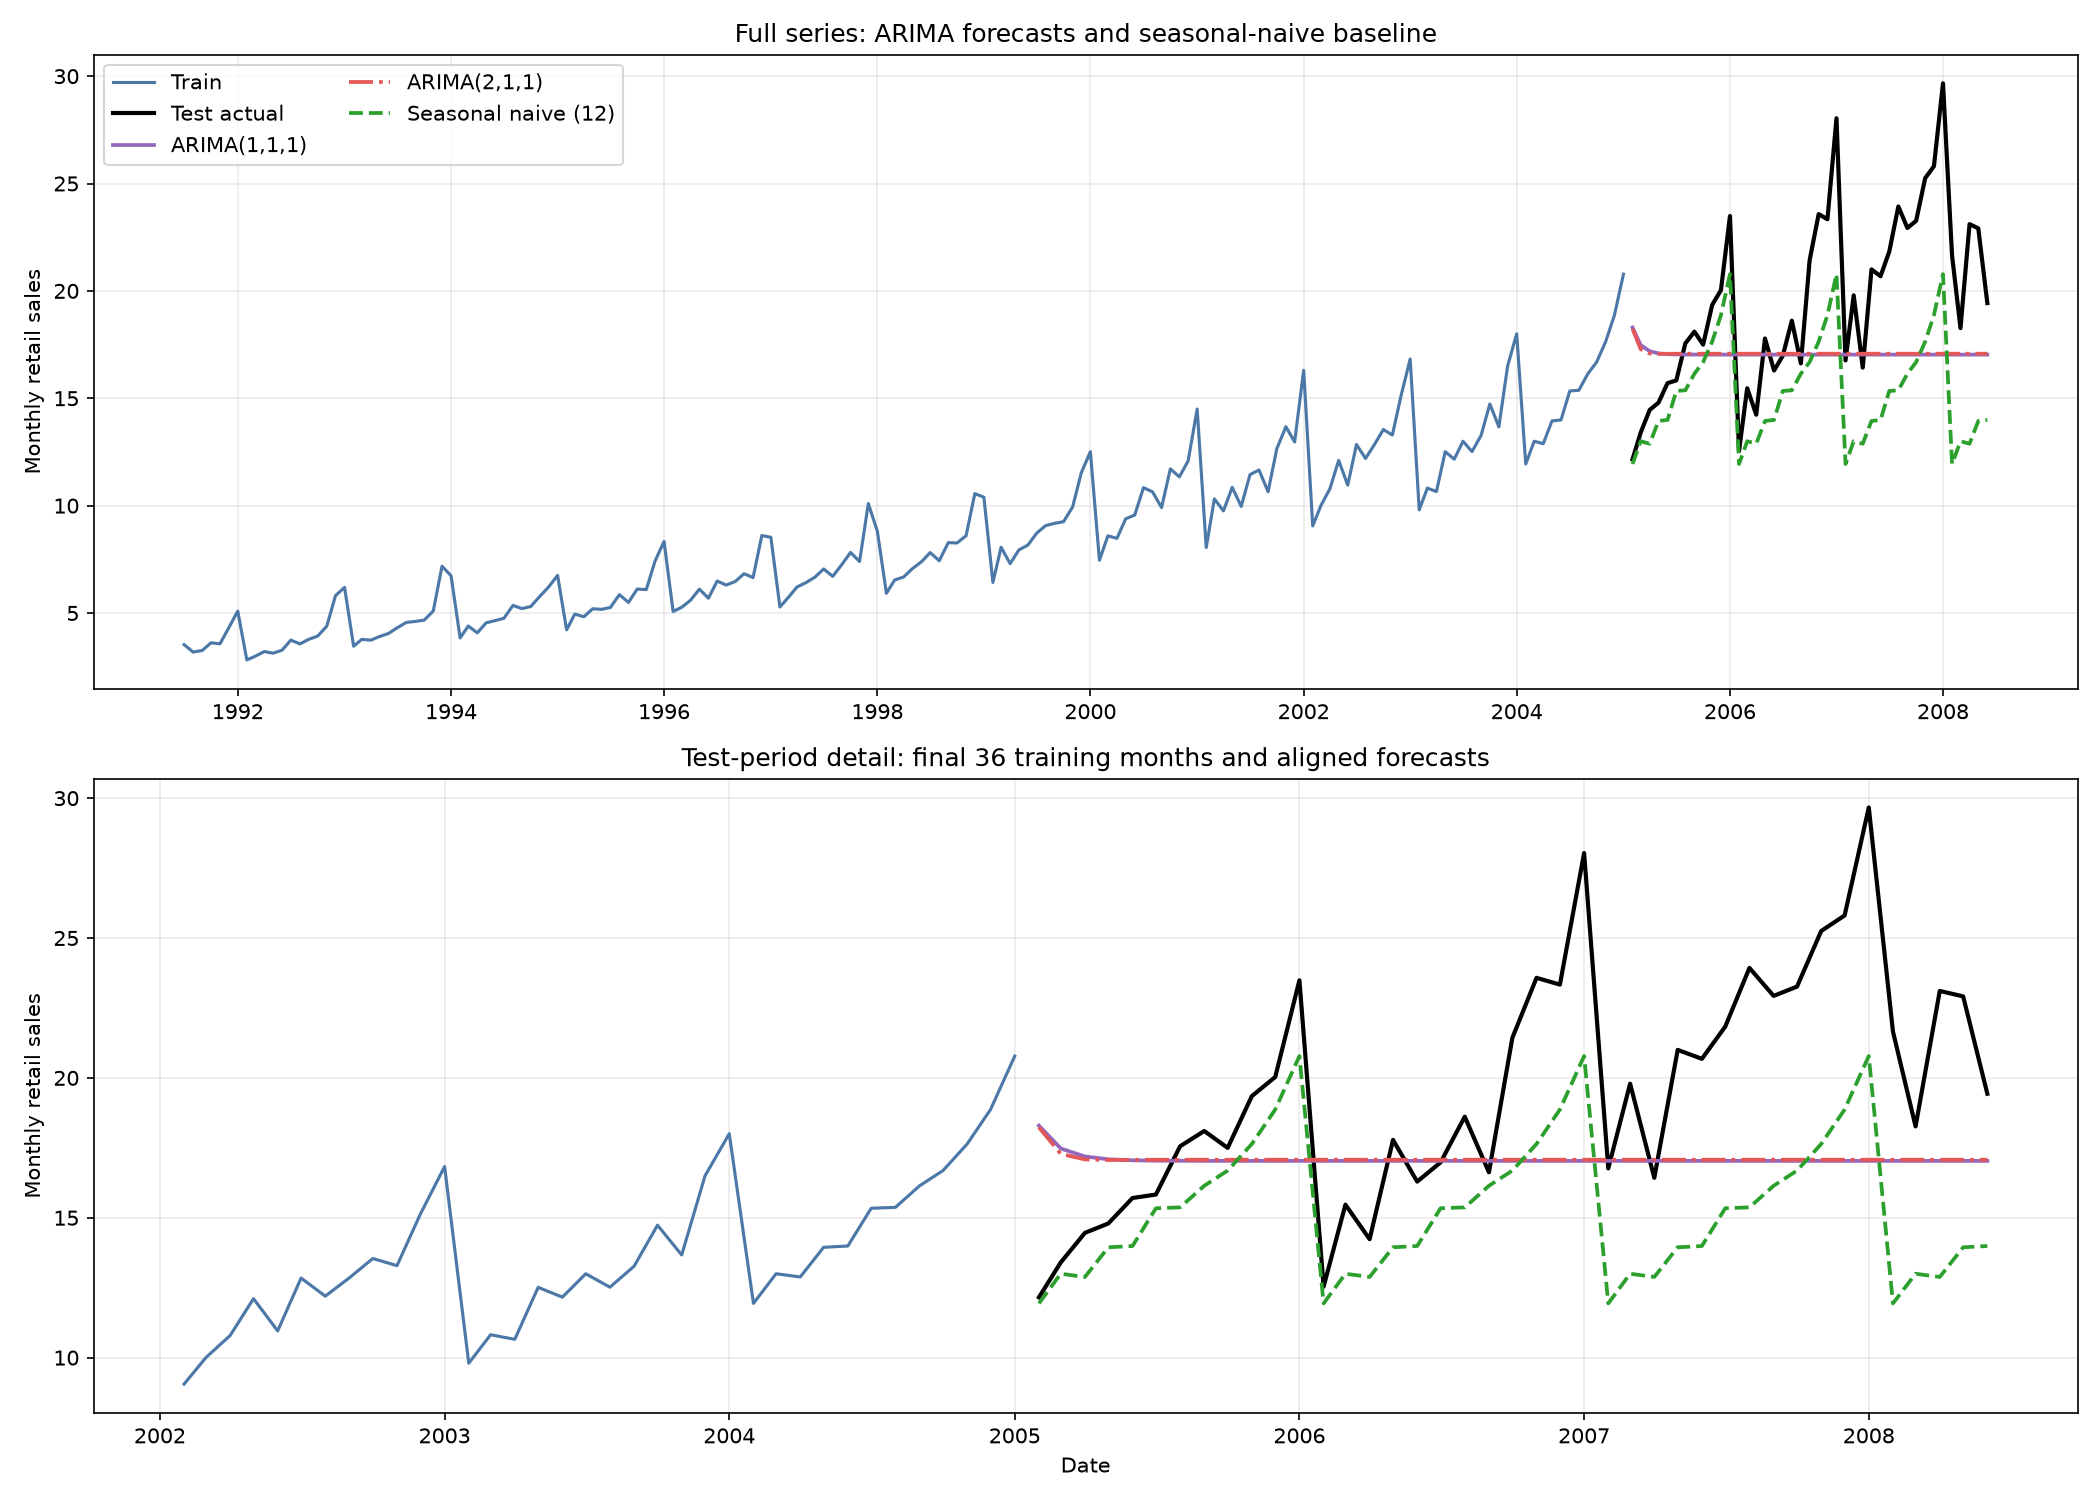

In [26]:
forecast_figure = FIGURES_DIR / '05_arima_forecast_comparison.png'
save_forecast_comparison_plot(e05_train, e05_test, e05_forecasts, forecast_figure)
display(Image(filename=str(forecast_figure)))

#### Largest absolute errors

In [27]:
display(Markdown('**Sai số tuyệt đối lớn nhất của từng mô hình**'))
display(largest_errors)

**Sai số tuyệt đối lớn nhất của từng mô hình**

,model,timestamp,actual,forecast,absolute_error
0,"ARIMA(1,1,1)",2008-01-01,29.665356,17.032717,12.632639
1,"ARIMA(2,1,1)",2008-01-01,29.665356,17.073746,12.591610
2,Seasonal naive (12),2008-04-01,23.107677,12.882645,10.225032


### 5. Kết luận E05

1. Chuỗi được chia theo thời gian, không shuffle; 41 tháng test chỉ dùng cho đánh giá cuối.
2. `p`, `d`, `q` lần lượt là bậc AR, số lần sai phân và bậc MA; hai candidate kế thừa `d=1` từ E3.
3. Cả hai model hội tụ, không phát sinh fitting warning và đều dùng cấu hình không drift (`trend='n'`). `ARIMA(1,1,1)` có AIC/BIC thấp hơn.
4. Residual mean lần lượt khoảng `0.0367` và `0.0371` trên log scale: tương đối nhỏ nhưng vẫn dương. Ljung–Box tại lag 12 và 24 có p-value rất nhỏ, nên residuals **không** được hỗ trợ là white noise.
5. Cần điều tra cấu trúc mùa vụ hoặc điều chỉnh order trong một scope mới; không tăng differencing tùy tiện.
6. Hai ARIMA forecast gần như phẳng, không bám được xu hướng tăng và các seasonal peaks. Đây là kết quả của specification không drift, không có seasonal component và AR/MA effects giảm dần trên horizon 41 tháng.
7. Largest error của hai ARIMA xảy ra tại `2008-01`; bảng trên cũng báo largest error của baseline.
8. RMSE nhạy nhất với sai số lớn vì bình phương error; MAPE có thể bất ổn khi actual gần 0.
9. RMSE tốt nhất khoảng `4.83`, tương đương khoảng `24.8%` test mean `19.51`; sai số vẫn đáng kể dù thấp hơn baseline `5.19` trên holdout này.

Inverse policy là `exp(log forecast mean)` không bias correction, nên kết quả được hiểu gần với conditional median trên thang gốc. `ARIMA(2,1,1)` có metric test thấp hơn nhẹ, nhưng không model nào đạt residual white-noise diagnostics; E05 không chốt một final ARIMA model hoàn toàn phù hợp.